# Tarea 3 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

Realiza las siguientes actividades:

1. Realiza 5 gráficas de visualización de datos al dataset de casas en Taiwán
2. Aplica cross validation al ejercicio de las casas de Taiwán
3. Visualiza 3 gráficas de insights y aplica Regresión logística con cross validation al
dataset abalone.csv

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

## Actividad 1

In [2]:
df = pd.read_csv("./casas_taiwan.csv").drop(columns=["No"])

df.head()

,fecha,edad,distancia_metro,tiendas,latitud,longitud,precio
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,114646.98
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,127654.43
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,143081.86
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,165769.25
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,130376.91


### 1. Correlación de variables

En esta gráfica se puede observar que en el precio influyen más el número de tiendas cercanas, la latitud y la longitud, mientras que la fecha, edad y la distancia al metro no tienen mucha influencia en el precio.

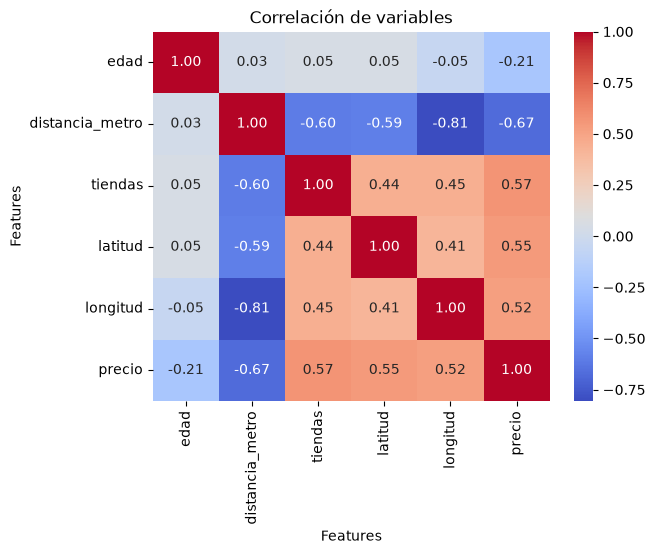

In [3]:
sns.heatmap(data=df.iloc[:, 1:].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlación de variables')
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

### 2. Distancia al metro vs. precio

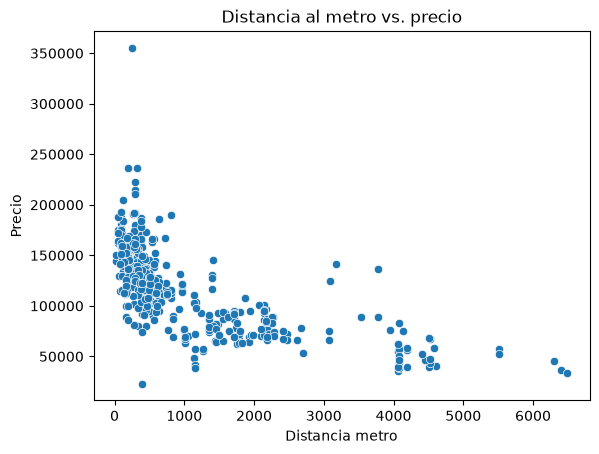

In [4]:
sns.scatterplot(data=df, x="distancia_metro", y="precio")
plt.title("Distancia al metro vs. precio")
plt.xlabel("Distancia metro")
plt.ylabel("Precio")
plt.show()

### 3. Distribución de precios

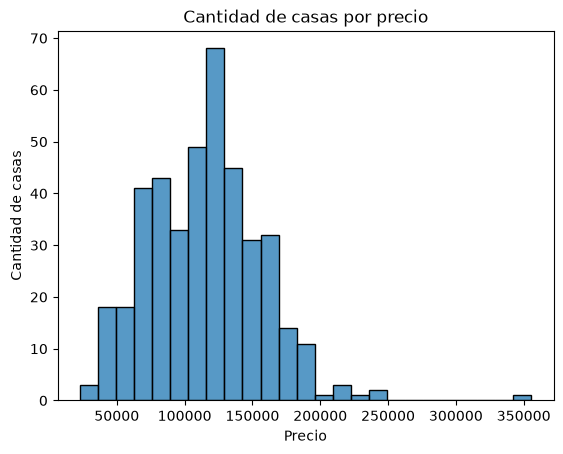

In [5]:
sns.histplot(data=df, x="precio", bins=25)
plt.title("Cantidad de casas por precio")
plt.xlabel("Precio")
plt.ylabel("Cantidad de casas")
plt.show()

### 4. Número de tiendas vs. precio

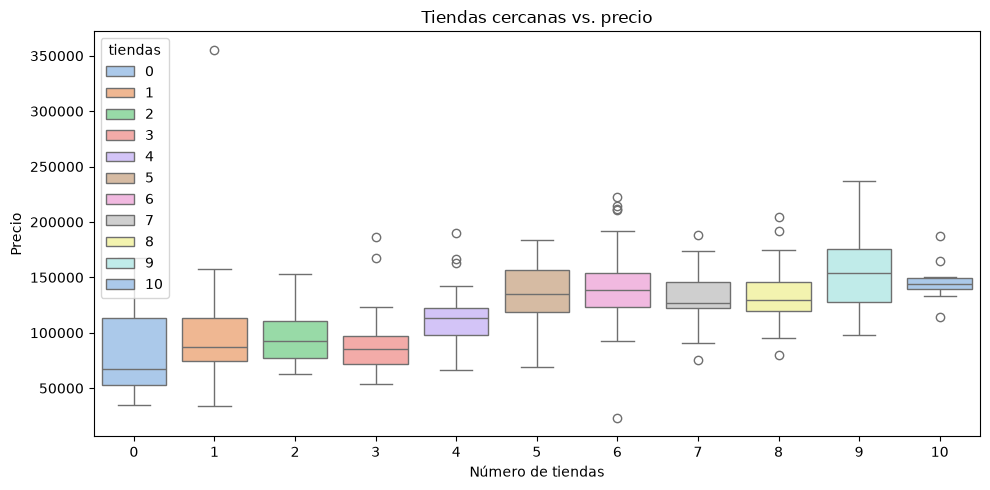

In [6]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="tiendas", y="precio", hue="tiendas", palette="pastel")
plt.title("Tiendas cercanas vs. precio")
plt.xlabel("Número de tiendas")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

### 5. Edad de la casa vs. precio

Como se observó en la gráfica de correlación de variables, la edad no influye directamente en el precio de la casa

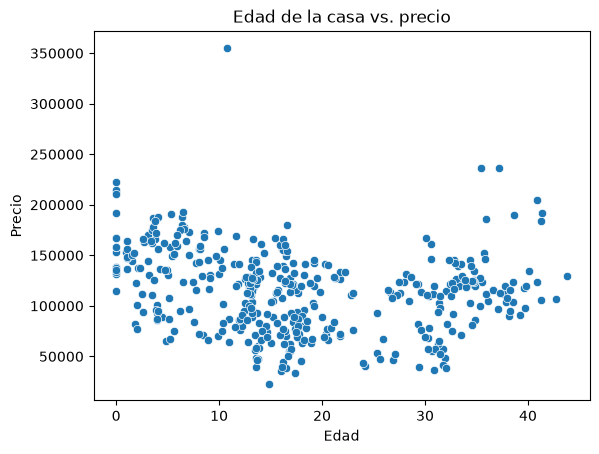

In [7]:
sns.scatterplot(data=df, x="edad", y="precio")
plt.title("Edad de la casa vs. precio")
plt.xlabel("Edad")
plt.ylabel("Precio")
plt.show()

## Actividad 2 - Cross validation

In [8]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

x = df[["fecha", "edad", "distancia_metro", "tiendas", "latitud", "longitud"]]
y = df["precio"]

model = Pipeline([("scaler", StandardScaler()), ("linear", LinearRegression())])

scoring_params = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

results = cross_validate(model, x, y, cv=10, scoring=scoring_params,
                         return_train_score=True, n_jobs=-1)

print(" Fold and metrics ".center(60, "-"))
for i in range(10):
    print(f"==> Fold {i + 1}")
    print(f"R2:   {results['test_r2'][i]:.4f}")
    print(f"MAE:  {-results['test_mae'][i]:.2f}")
    print(f"RMSE: {-results['test_rmse'][i]:.2f}")

print(" Mean Performance ".center(60, "="))
print(f"R2 test:   {results['test_r2'].mean():.4f}")
print(f"R2 train:  {results['train_r2'].mean():.4f}")
print(f"MAE test:  {-results['test_mae'].mean():.2f}")
print(f"RMSE test: {-results['test_rmse'].mean():.2f}")

--------------------- Fold and metrics ---------------------
==> Fold 1
R2:   0.6840
MAE:  17046.09
RMSE: 21807.24
==> Fold 2
R2:   0.7475
MAE:  16117.77
RMSE: 20768.19
==> Fold 3
R2:   0.5951
MAE:  21192.97
RMSE: 28396.97
==> Fold 4
R2:   0.3762
MAE:  21790.20
RMSE: 30522.27
==> Fold 5
R2:   0.7095
MAE:  14381.36
RMSE: 18977.21
==> Fold 6
R2:   0.6216
MAE:  16886.43
RMSE: 25151.07
==> Fold 7
R2:   0.3045
MAE:  23953.83
RMSE: 42578.77
==> Fold 8
R2:   0.5902
MAE:  20373.69
RMSE: 26316.56
==> Fold 9
R2:   0.6094
MAE:  15495.33
RMSE: 20790.65
==> Fold 10
R2:   0.5807
MAE:  20139.90
RMSE: 25864.63
===================== Mean Performance =====================
R2 test:   0.5819
R2 train:  0.5832
MAE test:  18737.76
RMSE test: 26117.36


## Actividad 3 - Dataset Abalone

In [9]:
df = pd.read_csv("./abalone.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


In [10]:
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


### 1. Correlación de variables

En la gráfica se observa que el número de anillos no tiene mucha relación con las demás variables (pesos y dimensiones).

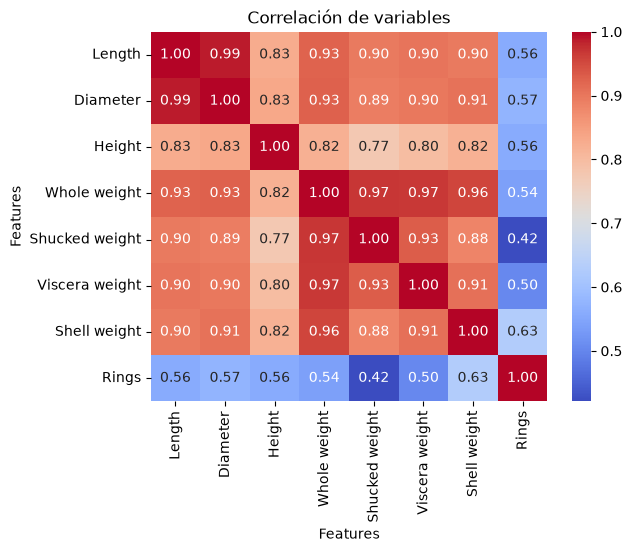

In [11]:
sns.heatmap(data=df.iloc[:, 1:].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlación de variables')
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

### 2. Anillos vs. Diámetro de la concha

La correlación de los anillos y el diámetro es de las variables que tienen más correlación entre sí (anillos respecto a las demás)

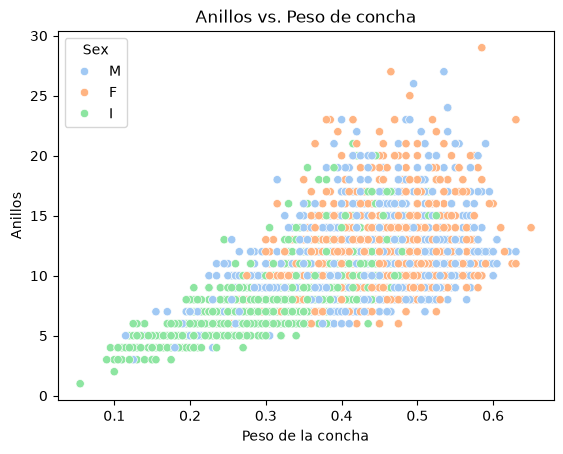

In [12]:
sns.scatterplot(data=df, x="Diameter", y="Rings", hue="Sex", palette="pastel")
plt.title("Anillos vs. Peso de concha")
plt.xlabel("Peso de la concha")
plt.ylabel("Anillos")
plt.show()

### 3. Distribución por sexo

La mayoría de los ejemplares son machos, luego infantes y finalmente hembras

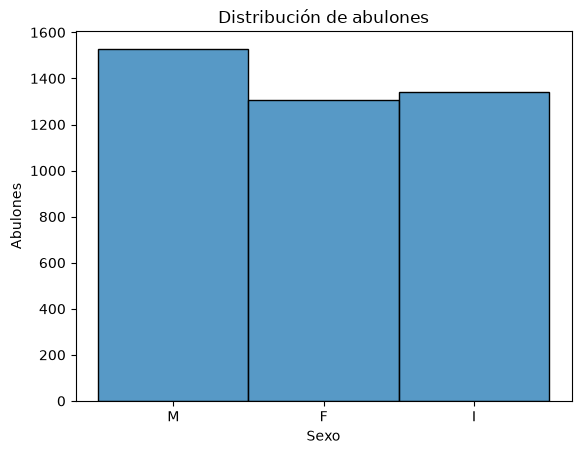

In [13]:
sns.histplot(data=df, x="Sex", bins=3)
plt.title("Distribución de abulones")
plt.xlabel("Sexo")
plt.ylabel("Abulones")
plt.show()

### 4. Regresión logística

Al aplicar regresión logística al dataset con 10 _folds_ se obtuvo un 78.33% de accuracy en promedio. Para este ejercicio se considera adulta una abalone si tiene más de 10 anillos.

==================[Accuracy on each fold]===================
Layer 1: 86.12%
Layer 2: 74.88%
Layer 3: 82.06%
Layer 4: 75.12%
Layer 5: 74.40%
Layer 6: 81.10%
Layer 7: 79.19%
Layer 8: 78.90%
Layer 9: 75.78%
Layer 10: 75.78%
Average accuracy: 78.33%
==================[Classification report]===================
              precision    recall  f1-score   support

           0       0.78      0.79      0.79      2096
           1       0.79      0.77      0.78      2081

    accuracy                           0.78      4177
   macro avg       0.78      0.78      0.78      4177
weighted avg       0.78      0.78      0.78      4177

=====================[Confusion Matrix]=====================
[[1661  435]
 [ 470 1611]]


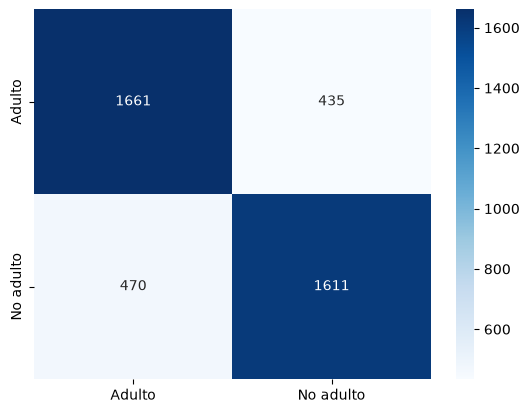

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression

df["Adult"] = (df["Rings"] >= 10).astype(int)
x = pd.get_dummies(data=df.drop(columns=["Rings", "Adult"]), columns=["Sex"], dtype=int)
y = df["Adult"]

model = Pipeline([("scaler", StandardScaler()), ("logistic_regression", LogisticRegression(max_iter=1000))])

results = cross_val_score(model, x, y, cv=10, scoring='accuracy')

print("[Accuracy on each fold]".center(60, '='))
for i, accuracy in enumerate(results, start=1):
    print(f"Layer {i}: {accuracy * 100:.2f}%")

print(f"Average accuracy: {results.mean() * 100:.2f}%")

y_pred_cv = cross_val_predict(model, x, y, cv=10)

matrix = confusion_matrix(y, y_pred_cv)

print("[Classification report]".center(60, '='))

print(classification_report(y, y_pred_cv))

print("[Confusion Matrix]".center(60, '='))
print(matrix)

sns.heatmap(matrix, annot=True, cmap='Blues', fmt='d',
            xticklabels=["Adulto", "No adulto"],
            yticklabels=["Adulto", "No adulto"])
plt.show()
